In [1]:
# Tiny Shakespeare — Train MiniGPT

## Objective

# Train our 3.2-million-parameter Transformer on the Tiny Shakespeare dataset using next-character prediction.

### Training pipeline

# 1. Load and tokenize the dataset.
# 2. Split into train / validation / test sets.
# 3. Build the MiniGPT model.
# 4. Define cross-entropy loss.
# 5. Define the AdamW optimizer.
# 6. Train the model.
# 7. Monitor training and validation loss.
# 8. Save the trained model.

In [2]:
import os
import math
import time

import torch
import torch.nn as nn
import torch.nn.functional as F

In [3]:
print("PyTorch:", torch.__version__)
print("MPS available:", torch.backends.mps.is_available())

PyTorch: 2.14.0
MPS available: True


In [4]:
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Training device:", device)

Training device: mps


In [5]:
vocab_size = 63
context_length = 128

embedding_dim = 256
num_heads = 4
num_layers = 4

dropout = 0.2

batch_size = 32

learning_rate = 3e-4
max_iterations = 5000

eval_interval = 500
eval_batches = 50

In [6]:
print("Training Configuration")
print("=" * 50)

print("Vocabulary size     :", vocab_size)
print("Context length      :", context_length)
print("Embedding dimension :", embedding_dim)
print("Attention heads     :", num_heads)
print("Transformer layers  :", num_layers)
print("Batch size          :", batch_size)
print("Learning rate       :", learning_rate)
print("Max iterations      :", max_iterations)

Training Configuration
Vocabulary size     : 63
Context length      : 128
Embedding dimension : 256
Attention heads     : 4
Transformer layers  : 4
Batch size          : 32
Learning rate       : 0.0003
Max iterations      : 5000


In [7]:
CLEAN_PATH = "../data/processed/tiny-shakespeare_clean.txt"

with open(CLEAN_PATH, "r", encoding="utf-8") as file:
    text = file.read()

print("Characters:", len(text))

Characters: 1114961


In [8]:
vocab = sorted(set(text))

stoi = {
    character: index
    for index, character in enumerate(vocab)
}

itos = {
    index: character
    for index, character in enumerate(vocab)
}

def encode(text):
    return [stoi[character] for character in text]

def decode(tokens):
    return "".join(
        itos[token]
        for token in tokens
    )

In [9]:
encoded_text = encode(text)

data = torch.tensor(
    encoded_text,
    dtype=torch.long
)

print("Vocabulary size:", len(vocab))
print("Total tokens:", len(data))

Vocabulary size: 63
Total tokens: 1114961


In [10]:
n = len(data)

train_end = int(0.90 * n)
val_end = int(0.95 * n)

train_data = data[:train_end]
val_data = data[train_end:val_end]
test_data = data[val_end:]

print("Train:", len(train_data))
print("Validation:", len(val_data))
print("Test:", len(test_data))

Train: 1003464
Validation: 55748
Test: 55749


In [11]:
def get_batch(
    data,
    batch_size,
    context_length
):

    starts = torch.randint(
        0,
        len(data) - context_length - 1,
        (batch_size,)
    )

    x = torch.stack([
        data[
            start:
            start + context_length
        ]
        for start in starts
    ])

    y = torch.stack([
        data[
            start + 1:
            start + context_length + 1
        ]
        for start in starts
    ])

    return x, y

In [12]:
x_batch, y_batch = get_batch(
    train_data,
    batch_size,
    context_length
)

print("X:", x_batch.shape)
print("Y:", y_batch.shape)

X: torch.Size([32, 128])
Y: torch.Size([32, 128])


In [13]:
x_batch, y_batch = get_batch(
    train_data,
    batch_size,
    context_length
)

print("X:", x_batch.shape)
print("Y:", y_batch.shape)

X: torch.Size([32, 128])
Y: torch.Size([32, 128])


In [14]:
class Head(nn.Module):

    def __init__(
        self,
        embedding_dim,
        head_dim,
        context_length,
        dropout
    ):
        super().__init__()

        self.key = nn.Linear(
            embedding_dim,
            head_dim,
            bias=False
        )

        self.query = nn.Linear(
            embedding_dim,
            head_dim,
            bias=False
        )

        self.value = nn.Linear(
            embedding_dim,
            head_dim,
            bias=False
        )

        self.dropout = nn.Dropout(dropout)

        self.register_buffer(
            "tril",
            torch.tril(
                torch.ones(
                    context_length,
                    context_length
                )
            )
        )

    def forward(self, x):

        B, T, C = x.shape

        k = self.key(x)
        q = self.query(x)

        attention_scores = q @ k.transpose(-2, -1)

        attention_scores = (
            attention_scores
            * (k.shape[-1] ** -0.5)
        )

        attention_scores = attention_scores.masked_fill(
            self.tril[:T, :T] == 0,
            float("-inf")
        )

        attention_weights = F.softmax(
            attention_scores,
            dim=-1
        )

        attention_weights = self.dropout(
            attention_weights
        )

        v = self.value(x)

        output = attention_weights @ v

        return output

In [15]:
class MultiHeadAttention(nn.Module):

    def __init__(
        self,
        embedding_dim,
        num_heads,
        context_length,
        dropout
    ):
        super().__init__()

        head_dim = embedding_dim // num_heads

        self.heads = nn.ModuleList([
            Head(
                embedding_dim,
                head_dim,
                context_length,
                dropout
            )
            for _ in range(num_heads)
        ])

        self.projection = nn.Linear(
            embedding_dim,
            embedding_dim
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        outputs = [
            head(x)
            for head in self.heads
        ]

        x = torch.cat(
            outputs,
            dim=-1
        )

        x = self.projection(x)

        x = self.dropout(x)

        return x

In [16]:
class FeedForward(nn.Module):

    def __init__(
        self,
        embedding_dim,
        dropout
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                embedding_dim,
                4 * embedding_dim
            ),

            nn.GELU(),

            nn.Linear(
                4 * embedding_dim,
                embedding_dim
            ),

            nn.Dropout(dropout)
        )

    def forward(self, x):
        return self.network(x)

In [17]:
class TransformerBlock(nn.Module):

    def __init__(
        self,
        embedding_dim,
        num_heads,
        context_length,
        dropout
    ):
        super().__init__()

        self.ln1 = nn.LayerNorm(
            embedding_dim
        )

        self.attention = MultiHeadAttention(
            embedding_dim,
            num_heads,
            context_length,
            dropout
        )

        self.ln2 = nn.LayerNorm(
            embedding_dim
        )

        self.ffn = FeedForward(
            embedding_dim,
            dropout
        )

    def forward(self, x):

        x = x + self.attention(
            self.ln1(x)
        )

        x = x + self.ffn(
            self.ln2(x)
        )

        return x

In [18]:
class MiniGPT(nn.Module):

    def __init__(
        self,
        vocab_size,
        context_length,
        embedding_dim,
        num_heads,
        num_layers,
        dropout
    ):
        super().__init__()

        self.context_length = context_length

        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        self.position_embedding = nn.Embedding(
            context_length,
            embedding_dim
        )

        self.blocks = nn.Sequential(
            *[
                TransformerBlock(
                    embedding_dim,
                    num_heads,
                    context_length,
                    dropout
                )
                for _ in range(num_layers)
            ]
        )

        self.ln_final = nn.LayerNorm(
            embedding_dim
        )

        self.lm_head = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, idx):

        B, T = idx.shape

        token_embeddings = self.token_embedding(idx)

        positions = torch.arange(
            T,
            device=idx.device
        )

        position_embeddings = self.position_embedding(
            positions
        )

        x = token_embeddings + position_embeddings

        x = self.blocks(x)

        x = self.ln_final(x)

        logits = self.lm_head(x)

        return logits

In [19]:
model = MiniGPT(
    vocab_size=vocab_size,
    context_length=context_length,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    dropout=dropout
)

model = model.to(device)

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

print(
    f"Total parameters: {total_parameters:,}"
)

Total parameters: 3,221,567


In [20]:
x_batch = x_batch.to(device)
y_batch = y_batch.to(device)

logits = model(x_batch)

print("Logits shape:", logits.shape)
print("Targets shape:", y_batch.shape)

Logits shape: torch.Size([32, 128, 63])
Targets shape: torch.Size([32, 128])


In [23]:
criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [24]:
loss = criterion(
    logits.view(-1, vocab_size),
    y_batch.view(-1)
)

print("Initial loss:", loss.item())

Initial loss: 4.302677631378174


In [25]:
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

print("Optimizer:", optimizer)

Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0003
    maximize: False
    weight_decay: 0.01
)


In [26]:
model.train()

x_batch, y_batch = get_batch(
    train_data,
    batch_size,
    context_length
)

x_batch = x_batch.to(device)
y_batch = y_batch.to(device)

optimizer.zero_grad()

logits = model(x_batch)

loss = criterion(
    logits.view(-1, vocab_size),
    y_batch.view(-1)
)

loss.backward()

optimizer.step()

print("Training step completed.")
print("Loss:", loss.item())

Training step completed.
Loss: 4.303005218505859


In [27]:
@torch.no_grad()
def estimate_loss():

    model.eval()

    results = {}

    for split_name, split_data in [
        ("train", train_data),
        ("val", val_data)
    ]:

        losses = torch.zeros(eval_batches)

        for i in range(eval_batches):

            x_batch, y_batch = get_batch(
                split_data,
                batch_size,
                context_length
            )

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(x_batch)

            loss = criterion(
                logits.view(-1, vocab_size),
                y_batch.view(-1)
            )

            losses[i] = loss.item()

        results[split_name] = losses.mean().item()

    model.train()

    return results

In [28]:
losses = estimate_loss()

print("Training loss  :", losses["train"])
print("Validation loss:", losses["val"])

Training loss  : 3.9912607669830322
Validation loss: 3.991532564163208


In [30]:
max_iterations = 20
eval_interval = 500

In [31]:
print("Starting training...")
print("=" * 60)

start_time = time.time()

for iteration in range(max_iterations):

    # Evaluate periodically
    if iteration % eval_interval == 0:

        losses = estimate_loss()

        elapsed = time.time() - start_time

        print(
            f"Step {iteration:5d} | "
            f"Train Loss: {losses['train']:.4f} | "
            f"Val Loss: {losses['val']:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    # Get training batch
    x_batch, y_batch = get_batch(
        train_data,
        batch_size,
        context_length
    )

    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)

    # Clear old gradients
    optimizer.zero_grad()

    # Forward pass
    logits = model(x_batch)

    # Calculate loss
    loss = criterion(
        logits.view(-1, vocab_size),
        y_batch.view(-1)
    )

    # Backward pass
    loss.backward()

    # Update model parameters
    optimizer.step()

print("=" * 60)
print("Training complete.")

Starting training...
Step     0 | Train Loss: 3.9924 | Val Loss: 3.9906 | Time: 4.5s
Training complete.


In [32]:
model = MiniGPT(
    vocab_size=vocab_size,
    context_length=context_length,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    dropout=dropout
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

criterion = nn.CrossEntropyLoss()

print("Model reset.")
print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Model reset.
Parameters: 3,221,567


In [33]:
max_iterations = 100
eval_interval = 20

print("Iterations:", max_iterations)
print("Evaluation interval:", eval_interval)

Iterations: 100
Evaluation interval: 20


In [34]:
print("Starting training...")
print("=" * 70)

start_time = time.time()

train_losses = []
val_losses = []
steps = []

for iteration in range(max_iterations):

    # Evaluate periodically
    if iteration % eval_interval == 0:

        losses = estimate_loss()

        elapsed = time.time() - start_time

        train_loss = losses["train"]
        val_loss = losses["val"]

        steps.append(iteration)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Step {iteration:5d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

    # Get a random training batch
    x_batch, y_batch = get_batch(
        train_data,
        batch_size,
        context_length
    )

    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)

    # Clear gradients
    optimizer.zero_grad()

    # Forward pass
    logits = model(x_batch)

    # Calculate loss
    loss = criterion(
        logits.view(-1, vocab_size),
        y_batch.view(-1)
    )

    # Backpropagation
    loss.backward()

    # Update parameters
    optimizer.step()

print("=" * 70)
print("Training complete.")

Starting training...
Step     0 | Train Loss: 4.2464 | Val Loss: 4.2427 | Time: 4.6s
Step    20 | Train Loss: 2.8608 | Val Loss: 2.8685 | Time: 11.7s
Step    40 | Train Loss: 2.6516 | Val Loss: 2.6515 | Time: 18.3s
Step    60 | Train Loss: 2.5748 | Val Loss: 2.5735 | Time: 24.9s
Step    80 | Train Loss: 2.5331 | Val Loss: 2.5342 | Time: 31.6s
Training complete.


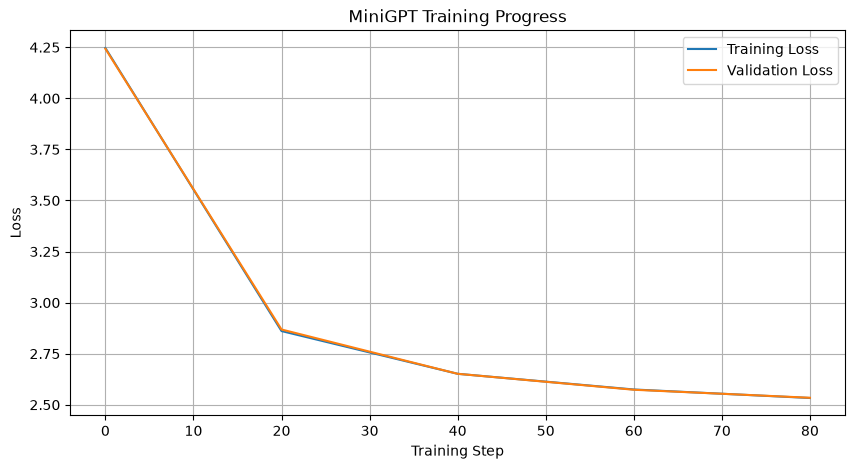

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    steps,
    train_losses,
    label="Training Loss"
)

plt.plot(
    steps,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("MiniGPT Training Progress")
plt.legend()
plt.grid(True)

plt.show()

In [37]:
import os

MODEL_DIR = "../models"

os.makedirs(
    MODEL_DIR,
    exist_ok=True
)

print("Model directory:", MODEL_DIR)

Model directory: ../models


In [38]:
model = MiniGPT(
    vocab_size=vocab_size,
    context_length=context_length,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    dropout=dropout
).to(device)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate
)

criterion = nn.CrossEntropyLoss()

print(
    "Parameters:",
    f"{sum(p.numel() for p in model.parameters()):,}"
)

print("Model reset successfully.")

Parameters: 3,221,567
Model reset successfully.


In [39]:
max_iterations = 5000
eval_interval = 500

train_losses = []
val_losses = []
steps = []

print("Max iterations:", max_iterations)
print("Evaluation every:", eval_interval)

Max iterations: 5000
Evaluation every: 500


In [40]:
print("Starting full training...")
print("=" * 75)

start_time = time.time()

for iteration in range(max_iterations + 1):

    # --------------------------------
    # Evaluation
    # --------------------------------
    if iteration % eval_interval == 0:

        losses = estimate_loss()

        train_loss = losses["train"]
        val_loss = losses["val"]

        elapsed = time.time() - start_time

        steps.append(iteration)
        train_losses.append(train_loss)
        val_losses.append(val_loss)

        print(
            f"Step {iteration:5d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Time: {elapsed:.1f}s"
        )

        # Save checkpoint
        checkpoint = {
            "iteration": iteration,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "train_loss": train_loss,
            "val_loss": val_loss,
            "vocab": vocab,
            "stoi": stoi,
            "itos": itos
        }

        checkpoint_path = os.path.join(
            MODEL_DIR,
            "minigpt_checkpoint.pt"
        )

        torch.save(
            checkpoint,
            checkpoint_path
        )

        print(
            f"Checkpoint saved: {checkpoint_path}"
        )

    # Don't train after the final evaluation
    if iteration == max_iterations:
        break

    # --------------------------------
    # Get training batch
    # --------------------------------

    x_batch, y_batch = get_batch(
        train_data,
        batch_size,
        context_length
    )

    x_batch = x_batch.to(device)
    y_batch = y_batch.to(device)

    # --------------------------------
    # Forward pass
    # --------------------------------

    optimizer.zero_grad()

    logits = model(x_batch)

    # --------------------------------
    # Calculate loss
    # --------------------------------

    loss = criterion(
        logits.view(-1, vocab_size),
        y_batch.view(-1)
    )

    # --------------------------------
    # Backpropagation
    # --------------------------------

    loss.backward()

    # --------------------------------
    # Update parameters
    # --------------------------------

    optimizer.step()

print("=" * 75)
print("Full training complete.")

Starting full training...
Step     0 | Train Loss: 4.3433 | Val Loss: 4.3397 | Time: 4.4s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step   500 | Train Loss: 2.0968 | Val Loss: 2.1251 | Time: 73.9s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step  1000 | Train Loss: 1.7946 | Val Loss: 1.8989 | Time: 141.3s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step  1500 | Train Loss: 1.6524 | Val Loss: 1.7725 | Time: 208.4s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step  2000 | Train Loss: 1.5679 | Val Loss: 1.6837 | Time: 274.8s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step  2500 | Train Loss: 1.4940 | Val Loss: 1.6335 | Time: 341.8s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step  3000 | Train Loss: 1.4461 | Val Loss: 1.5814 | Time: 408.8s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step  3500 | Train Loss: 1.4192 | Val Loss: 1.5523 | Time: 475.5s
Checkpoint saved: ../models/minigpt_checkpoint.pt
Step  4000 | Train Loss: 1.3936 | Val Loss: 1.534

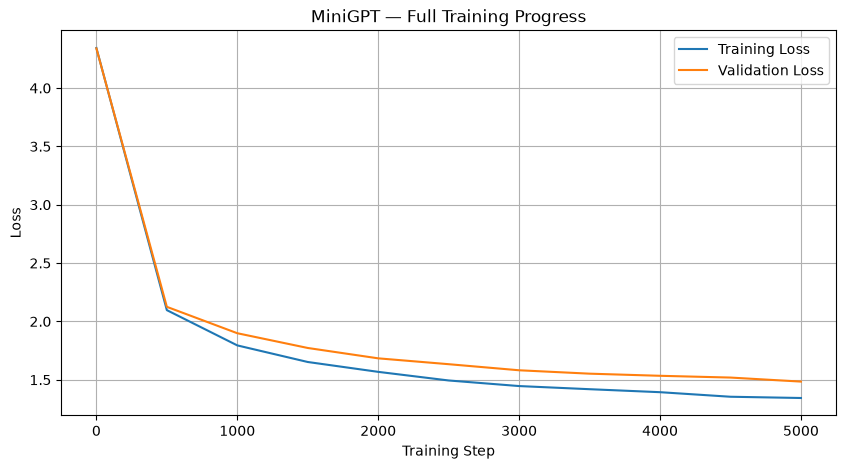

In [41]:
plt.figure(figsize=(10, 5))

plt.plot(
    steps,
    train_losses,
    label="Training Loss"
)

plt.plot(
    steps,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.title("MiniGPT — Full Training Progress")
plt.legend()
plt.grid(True)

plt.show()